# CS3807 Exp 8 & 9 - Attention Type and Position in a Pretrained ResNet50
Dataset: `tf_flowers` (70/15/15 fixed split) · Backbone: ResNet50 (ImageNet) · Positions: **P1..P4 = after conv2_x..conv5_x**



In [ ]:
!pip install -q tensorflow tensorflow-datasets scikit-learn pandas matplotlib

In [ ]:
import os, json, time, gc, collections
import numpy as np, pandas as pd, tensorflow as tf, tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from IPython.display import display
from tensorflow import keras
from tensorflow.keras import layers as L
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score

# ---- identical for every experiment ----
SEEDS      = [42]          # [42, 7, 123] -> mean ± std (3x the time)
SPLIT_SEED = 42
BS         = 32
EP_HEAD, EP_FT = 5, 5      # frozen-backbone epochs, then conv5_x fine-tune epochs
LR_HEAD, LR_FT = 1e-3, 1e-4
RUN_P1     = True          # P1 (56x56) is slow/memory heavy; set False if Colab runs out of memory
WEIGHTS    = "imagenet"
QUICK      = False         # True = tiny smoke test
OUT = "results"; os.makedirs(OUT + "/ckpt", exist_ok=True)

## 1. Dataset (fixed 70 : 15 : 15 split)

In [ ]:
'''(tr, va, te), info = tfds.load("tf_flowers", split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
                               as_supervised=True, with_info=True)
CLASSES = info.features["label"].names'''
import pathlib, random
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = keras.utils.get_file("flower_photos.tgz", origin=url, extract=True)
base = pathlib.Path(archive).parent

unique = {}                                                   # (class, filename) -> path  => drops the duplicate extraction
for p in sorted(base.rglob("*.jpg")):
    unique.setdefault((p.parent.name, p.name), p)
CLASSES = sorted({c for c, _ in unique})
files = [(str(p), CLASSES.index(c)) for (c, _), p in sorted(unique.items())]
print(CLASSES, len(files), "unique images")
assert len(files) == 3670 and len(CLASSES) == 5, "unexpected dataset contents (see printout above)"

random.Random(SPLIT_SEED).shuffle(files)                      # fixed seed -> identical split every run
n = len(files); a, b = int(0.70 * n), int(0.85 * n)

def make_ds(items):
    paths = tf.constant([p for p, _ in items], dtype=tf.string)
    ys = tf.constant([y for _, y in items], dtype=tf.int64)
    return tf.data.Dataset.from_tensor_slices((paths, ys)).map(
        lambda p, y: (tf.io.decode_jpeg(tf.io.read_file(p), channels=3), y), tf.data.AUTOTUNE)

tr, va, te = make_ds(files[:a]), make_ds(files[a:b]), make_ds(files[b:])
print("split:", a, b - a, n - b)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips'] 3670 unique images
split: 2569 550 551


551 test images | per-class: {'daisy': np.int64(105), 'dandelion': np.int64(141), 'roses': np.int64(80), 'sunflowers': np.int64(112), 'tulips': np.int64(113)}


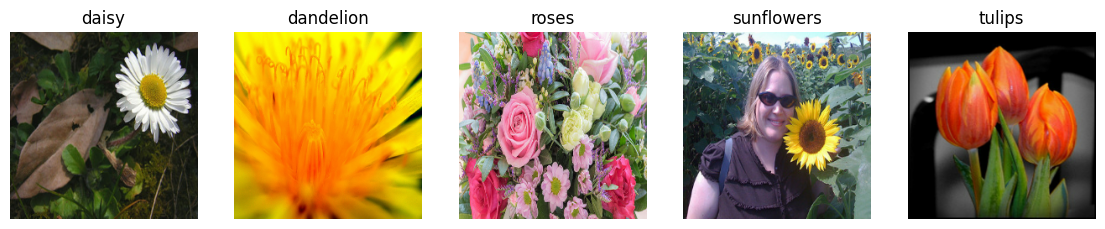

In [ ]:
if QUICK: tr, va, te = tr.take(96), va.take(32), te.take(32)

def preprocess(x):
    return keras.applications.resnet50.preprocess_input(tf.image.resize(tf.cast(x, tf.float32), (224, 224)))
def mk(d, shuffle=False):
    if shuffle: d = d.shuffle(1024, seed=SPLIT_SEED)
    return d.map(lambda x, y: (preprocess(x), y), tf.data.AUTOTUNE).batch(BS).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = mk(tr, True), mk(va), mk(te)
test_raw = np.stack([tf.image.resize(x, (224, 224)).numpy().astype("uint8") for x, _ in te])
test_y   = np.array([int(y) for _, y in te])
prep_np  = lambda i: keras.applications.resnet50.preprocess_input(test_raw[i].astype("float32"))
print(len(test_y), "test images | per-class:", dict(zip(CLASSES, np.bincount(test_y, minlength=5))))

# required viz 1: sample images from all five classes
seen = {}
for x, y in tr:
    seen.setdefault(int(y), tf.image.resize(x, (224, 224)).numpy().astype("uint8"))
    if len(seen) == 5: break
fig, ax = plt.subplots(1, 5, figsize=(14, 3))
for c in sorted(seen): ax[c].imshow(seen[c]); ax[c].set_title(CLASSES[c]); ax[c].axis("off")
plt.show()

## 2. Attention modules (channel/SE, ECA, spatial, CBAM, self-attention, coordinate attention)

In [ ]:
class CA(L.Layer):                       # channel attention == SE (r = 16)
    def __init__(s, r=16, **k): super().__init__(**k); s.r = r
    def build(s, sh):
        c = sh[-1]; s.f1 = L.Dense(max(c // s.r, 1), activation="relu"); s.f2 = L.Dense(c, activation="sigmoid")
    def weights_of(s, x): return s.f2(s.f1(tf.reduce_mean(x, [1, 2])))
    def call(s, x): return x * s.weights_of(x)[:, None, None, :]

class ECA(L.Layer):                      # efficient channel attention (1-D conv over channel descriptor)
    def __init__(s, k=3, **kw): super().__init__(**kw); s.conv = L.Conv1D(1, k, padding="same", activation="sigmoid")
    def weights_of(s, x): return s.conv(tf.reduce_mean(x, [1, 2])[..., None])[..., 0]
    def call(s, x): return x * s.weights_of(x)[:, None, None, :]

class SA(L.Layer):                       # spatial attention (kernel k)
    def __init__(s, k=7, **kw): super().__init__(**kw); s.conv = L.Conv2D(1, k, padding="same", activation="sigmoid")
    def get_map(s, x):
        return s.conv(tf.concat([tf.reduce_mean(x, -1, keepdims=True), tf.reduce_max(x, -1, keepdims=True)], -1))
    def call(s, x): return x * s.get_map(x)

class CBAM(L.Layer):                     # 'cs' = Channel->Spatial, 'sc' = Spatial->Channel
    def __init__(s, order="cs", k=7, **kw): super().__init__(**kw); s.order = order; s.ca = CA(); s.sa = SA(k)
    def get_map(s, x): return s.sa.get_map(s.ca(x) if s.order == "cs" else x)
    def call(s, x): return s.sa(s.ca(x)) if s.order == "cs" else s.ca(s.sa(x))

class SelfAttn(L.Layer):                 # lightweight self-attention; F + gamma * reshape(softmax(QK^T/sqrt(d)) V)
    def build(s, sh):
        _, s.H, s.W, c = sh; s.d = max(c // 8, 8)
        s.q, s.k, s.v = L.Dense(s.d), L.Dense(s.d), L.Dense(c)
        s.gamma = s.add_weight(name="gamma", shape=(), initializer="zeros")
    def call(s, x, return_attn=False):
        c = x.shape[-1]; X = tf.reshape(x, (-1, s.H * s.W, c))
        A = tf.nn.softmax(tf.matmul(s.q(X), s.k(X), transpose_b=True) / np.sqrt(s.d))   # N x N
        y = tf.reshape(tf.matmul(A, s.v(X)), (-1, s.H, s.W, c))
        out = x + s.gamma * y
        return (out, A) if return_attn else out

class CoordAtt(L.Layer):                 # coordinate attention
    def build(s, sh):
        _, s.H, s.W, c = sh; mip = max(8, c // 32)
        s.c1, s.bn = L.Conv2D(mip, 1), L.BatchNormalization()
        s.ch, s.cw = L.Conv2D(c, 1, activation="sigmoid"), L.Conv2D(c, 1, activation="sigmoid")
    def call(s, x, training=None):
        xh = tf.reduce_mean(x, 2, keepdims=True)                                   # B,H,1,C
        xw = tf.transpose(tf.reduce_mean(x, 1, keepdims=True), [0, 2, 1, 3])       # B,W,1,C
        y = s.bn(s.c1(tf.concat([xh, xw], 1)), training=training)
        y = y * tf.nn.relu6(y + 3.0) / 6.0                                         # h-swish
        yh, yw = tf.split(y, [s.H, s.W], axis=1)
        return x * s.ch(yh) * tf.transpose(s.cw(yw), [0, 2, 1, 3])

SPATIAL_TYPES = ("spatial", "cs", "sc", "combined")
def make_att(name, k=7):
    return {"channel": lambda: CA(), "eca": lambda: ECA(), "spatial": lambda: SA(k),
            "cs": lambda: CBAM("cs", k), "sc": lambda: CBAM("sc", k), "self": lambda: SelfAttn(),
            "coord": lambda: CoordAtt(), "combined": lambda: keras.Sequential([CBAM("cs", k), SelfAttn()])}[name]()

## 3. ResNet50 split into stages (P1..P4) with attention inserted after any stage

In [ ]:
CUTS = ["conv2_block3_out", "conv3_block4_out", "conv4_block6_out", "conv5_block3_out"]   # P1..P4

class Net(keras.Model):
    def __init__(s, att=None, k=7):          # att = {position(1..4): attention name}
        super().__init__()
        base = keras.applications.ResNet50(weights=WEIGHTS, include_top=False, input_shape=(224, 224, 3))
        ins = [base.input] + [base.get_layer(c).output for c in CUTS[:-1]]
        s.stages = [keras.Model(i, base.get_layer(c).output) for i, c in zip(ins, CUTS)]
        s.atts = {f"p{p}": make_att(a, k) for p, a in (att or {}).items()}
        s.aug = keras.Sequential([L.RandomFlip("horizontal"), L.RandomRotation(0.05), L.RandomZoom(0.1),
                                  L.RandomTranslation(0.05, 0.05), L.RandomContrast(0.1)])
        s.gap, s.drop, s.fc = L.GlobalAveragePooling2D(), L.Dropout(0.3), L.Dense(5)
    def call(s, x, training=False, return_feat=False):
        if training: x = s.aug(x, training=True)
        for i, st in enumerate(s.stages, 1):
            x = st(x, training=training)
            if f"p{i}" in s.atts: x = s.atts[f"p{i}"](x)
        out = s.fc(s.drop(s.gap(x), training=training))
        return (out, x) if return_feat else out

def set_trainable(net, open_last):           # backbone frozen; optionally open conv5_x; BN always frozen
    for i, st in enumerate(net.stages, 1):
        st.trainable = bool(open_last and i == 4)
        for l in st.layers:
            if isinstance(l, L.BatchNormalization): l.trainable = False

def compile_(net, lr):
    net.compile(keras.optimizers.Adam(lr), keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])

def attention_dims(net):                     # feature dims immediately before/after every attention block
    h, out = tf.zeros((1, 224, 224, 3)), {}
    for i, st in enumerate(net.stages, 1):
        h = st(h, training=False)
        if f"p{i}" in net.atts:
            a = net.atts[f"p{i}"](h); out[f"P{i}"] = (tuple(h.shape[1:]), tuple(a.shape[1:])); h = a
    return out

## 4. Train / evaluate one configuration (cached to disk)

In [ ]:
def infer_ms(net, n=100):                    # average latency per image, batch = 1, after warm-up
    f = tf.function(lambda x: net(x, training=False))
    n = min(n, len(test_raw)); xs = [tf.constant(prep_np(i)[None]) for i in range(n)]
    for _ in range(10): f(xs[0]).numpy()
    t0 = time.perf_counter()
    for x in xs: f(x).numpy()
    return (time.perf_counter() - t0) / n * 1000

def train_one(att, k, seed):
    key = key_of(att, k); path = f"{OUT}/{key}_s{seed}.json"
    if os.path.exists(path): return json.load(open(path))
    keras.utils.set_random_seed(seed)
    net = Net(att, k); net(tf.zeros((1, 224, 224, 3)))
    set_trainable(net, False); compile_(net, LR_HEAD)
    h1 = net.fit(train_ds, validation_data=val_ds, epochs=EP_HEAD, verbose=2)
    set_trainable(net, True);  compile_(net, LR_FT)
    h2 = net.fit(train_ds, validation_data=val_ds, epochs=EP_FT, verbose=2)
    hist = {m: [float(v) for v in h1.history[m] + h2.history[m]] for m in h1.history}
    y_pred = net.predict(test_ds, verbose=0).argmax(1); assert len(y_pred) == len(test_y)
    p, r, f, _ = precision_recall_fscore_support(test_y, y_pred, average="macro", zero_division=0)
    pc = precision_recall_fscore_support(test_y, y_pred, average=None, zero_division=0)[2]
    res = dict(Accuracy=float(accuracy_score(test_y, y_pred)), Precision=float(p), Recall=float(r), F1=float(f),
               Trainable=int(sum(np.prod(w.shape) for w in net.trainable_weights)),
               TotalParams=int(net.count_params()),
               AttnParams=int(sum(a.count_params() for a in net.atts.values())),
               ms_per_img=float(infer_ms(net)),
               TrainAcc=hist["accuracy"][-1], ValAcc=hist["val_accuracy"][-1],
               TrainLoss=hist["loss"][-1], ValLoss=hist["val_loss"][-1],
               hist=hist, y_pred=y_pred.tolist(), f1_per_class=[float(v) for v in pc],
               dims={a: [list(b[0]), list(b[1])] for a, b in attention_dims(net).items()})
    json.dump(res, open(path, "w"))
    if seed == SEEDS[0]: net.save_weights(f"{OUT}/ckpt/{key}.weights.h5")
    del net; keras.backend.clear_session(); gc.collect()
    return res

## 5. Experiment registry (A: type · B: position · C: multi-stage · D: order · E: kernel · F: additional)

In [ ]:
def key_of(att, k=7):
    if not att: return "baseline"
    sp = any(a in SPATIAL_TYPES for a in att.values())
    return "_".join(f"P{p}{a}" for p, a in sorted(att.items())) + (f"_k{k}" if sp else "")

NAMED = collections.OrderedDict()
def reg(name, att, k=7):
    NAMED[name] = (att, k if any(a in SPATIAL_TYPES for a in att.values()) else 7)

reg("A0 Baseline", {})
reg("A1 Channel(SE)@P3", {3: "channel"})
reg("A2 Spatial@P3", {3: "spatial"})
reg("A3 Ch+Sp(CBAM)@P3", {3: "cs"})            # = B3 = kernel 7 = CBAM
reg("A4 SelfAttn@P3", {3: "self"})
reg("A5 Combined@P3", {3: "combined"})          # Channel + Spatial + Self-attention
if RUN_P1: reg("B1 Ch+Sp@P1", {1: "cs"})
reg("B2 Ch+Sp@P2", {2: "cs"})
reg("B4 Ch+Sp@P4", {4: "cs"})
reg("C1 Ch+Sp@P3+P4", {3: "cs", 4: "cs"})
reg("C2 Ch+Sp@P2+P3+P4", {2: "cs", 3: "cs", 4: "cs"})
reg("D1 Sp->Ch@P3", {3: "sc"})
reg("E1 Ch+Sp@P3 k=3", {3: "cs"}, 3)
reg("E2 Ch+Sp@P3 k=5", {3: "cs"}, 5)
reg("F1 ECA@P3", {3: "eca"})
reg("F2 CoordAtt@P3", {3: "coord"})

ALIAS = {"B3 Ch+Sp@P3": "A3 Ch+Sp(CBAM)@P3", "E3 Ch+Sp@P3 k=7": "A3 Ch+Sp(CBAM)@P3",
         "CBAM@P3": "A3 Ch+Sp(CBAM)@P3", "SE@P3": "A1 Channel(SE)@P3", "SelfAttn@P3": "A4 SelfAttn@P3"}
print(len({key_of(*v) for v in NAMED.values()}), "unique models |", len(NAMED), "named configurations")

16 unique models | 16 named configurations


## 6. Run everything (resumable; ~15 unique models × (EP_HEAD+EP_FT) epochs)

In [ ]:
todo = {key_of(a, k): (a, k) for a, k in NAMED.values()}
for key, (a, k) in todo.items():
    for sd in SEEDS:
        r = train_one(a, k, sd); print(f"{key:28s} seed {sd}  acc {r['Accuracy']:.4f}  F1 {r['F1']:.4f}  {r['ms_per_img']:.1f} ms/img")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Epoch 1/5
81/81 - 26s - 322ms/step - accuracy: 0.6318 - loss: 0.9876 - val_accuracy: 0.7818 - val_loss: 0.5722
Epoch 2/5
81/81 - 13s - 162ms/step - accuracy: 0.8124 - loss: 0.5433 - val_accuracy: 0.8236 - val_loss: 0.4826
Epoch 3/5
81/81 - 13s - 165ms/step - accuracy: 0.8385 - loss: 0.4733 - val_accuracy: 0.8182 - val_loss: 0.5007
Epoch 4/5
81/81 - 14s - 167ms/step - accuracy: 0.8599 - loss: 0.3961 - val_accuracy: 0.8709 - val_loss: 0.3741
Epoch 5/5
81/81 - 14s - 167ms/step - accuracy: 0.8599 - loss: 0.3740 - val_accuracy: 0.8582 - val_loss: 0.4185
Epoch 1/5
81/81 - 28s - 344ms/step - accuracy: 0.8540 - loss: 0.4085 - val_accuracy: 0.8364 - val_loss: 0.4946
Epoch 2/5
81/81 - 17s - 208ms/step - accuracy: 0.9004 - loss: 0.2693 - val_accuracy: 0.9091 - val_loss: 0.3077
Epoch 3/5
81/81 - 17s - 209ms/step - accuracy: 0.9327 - loss: 0.1831 - val_accuracy: 0.9127 - val_loss: 0.3161
Epoch 4/5
81/81 - 17s - 208ms/step - accuracy: 0.9463 - loss: 0.1457 - val_accuracy: 0.8782 - val_loss: 0.5823
E

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Epoch 1/5
81/81 - 24s - 290ms/step - accuracy: 0.6508 - loss: 0.8997 - val_accuracy: 0.7345 - val_loss: 0.6645
Epoch 2/5
81/81 - 15s - 185ms/step - accuracy: 0.8159 - loss: 0.4804 - val_accuracy: 0.8509 - val_loss: 0.4136
Epoch 3/5
81/81 - 15s - 186ms/step - accuracy: 0.8540 - loss: 0.3989 - val_accuracy: 0.7909 - val_loss: 0.5246
Epoch 4/5
81/81 - 15s - 183ms/step - accuracy: 0.8770 - loss: 0.3381 - val_accuracy: 0.8400 - val_loss: 0.4064
Epoch 5/5
81/81 - 15s - 183ms/step - accuracy: 0.8719 - loss: 0.3353 - val_accuracy: 0.8291 - val_loss: 0.4754
Epoch 1/5
81/81 - 29s - 356ms/step - accuracy: 0.8513 - loss: 0.4176 - val_accuracy: 0.8382 - val_loss: 0.4546
Epoch 2/5
81/81 - 18s - 216ms/step - accuracy: 0.8996 - loss: 0.2716 - val_accuracy: 0.9018 - val_loss: 0.2791
Epoch 3/5
81/81 - 18s - 218ms/step - accuracy: 0.9323 - loss: 0.1978 - val_accuracy: 0.9273 - val_loss: 0.3259
Epoch 4/5
81/81 - 17s - 214ms/step - accuracy: 0.9420 - loss: 0.1676 - val_accuracy: 0.9036 - val_loss: 0.3980
E

...

Epoch 1/5
81/81 - 24s - 296ms/step - accuracy: 0.6547 - loss: 0.8638 - val_accuracy: 0.7091 - val_loss: 0.7081
Epoch 2/5
81/81 - 15s - 190ms/step - accuracy: 0.8202 - loss: 0.4737 - val_accuracy: 0.7891 - val_loss: 0.5750
Epoch 3/5
81/81 - 15s - 190ms/step - accuracy: 0.8540 - loss: 0.4061 - val_accuracy: 0.7855 - val_loss: 0.5563
Epoch 4/5
81/81 - 15s - 187ms/step - accuracy: 0.8747 - loss: 0.3449 - val_accuracy: 0.7927 - val_loss: 0.5487
Epoch 5/5
81/81 - 15s - 184ms/step - accuracy: 0.8824 - loss: 0.3308 - val_accuracy: 0.8109 - val_loss: 0.4938
Epoch 1/5
81/81 - 28s - 351ms/step - accuracy: 0.8369 - loss: 0.4322 - val_accuracy: 0.8691 - val_loss: 0.3581
Epoch 2/5
81/81 - 18s - 220ms/step - accuracy: 0.8949 - loss: 0.2904 - val_accuracy: 0.8727 - val_loss: 0.3571
Epoch 3/5
81/81 - 18s - 220ms/step - accuracy: 0.9299 - loss: 0.1901 - val_accuracy: 0.9055 - val_loss: 0.3057
Epoch 4/5
81/81 - 18s - 217ms/step - accuracy: 0.9451 - loss: 0.1528 - val_accuracy: 0.8982 - val_loss: 0.4009
E

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Epoch 1/5
81/81 - 24s - 292ms/step - accuracy: 0.4013 - loss: 1.4397 - val_accuracy: 0.6055 - val_loss: 1.1382
Epoch 2/5
81/81 - 15s - 186ms/step - accuracy: 0.6431 - loss: 1.0107 - val_accuracy: 0.7491 - val_loss: 0.7363
Epoch 3/5
81/81 - 15s - 186ms/step - accuracy: 0.7458 - loss: 0.7015 - val_accuracy: 0.7655 - val_loss: 0.6476
Epoch 4/5
81/81 - 15s - 183ms/step - accuracy: 0.7953 - loss: 0.5576 - val_accuracy: 0.7982 - val_loss: 0.5394
Epoch 5/5
81/81 - 15s - 181ms/step - accuracy: 0.8139 - loss: 0.5059 - val_accuracy: 0.8073 - val_loss: 0.5151
Epoch 1/5
81/81 - 28s - 343ms/step - accuracy: 0.8178 - loss: 0.5242 - val_accuracy: 0.8727 - val_loss: 0.3353
Epoch 2/5
81/81 - 18s - 217ms/step - accuracy: 0.8856 - loss: 0.3327 - val_accuracy: 0.8873 - val_loss: 0.2873
Epoch 3/5
81/81 - 18s - 217ms/step - accuracy: 0.9066 - loss: 0.2546 - val_accuracy: 0.8455 - val_loss: 0.5498
Epoch 4/5
81/81 - 17s - 213ms/step - accuracy: 0.9229 - loss: 0.2055 - val_accuracy: 0.9218 - val_loss: 0.2682
E

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Epoch 1/5
81/81 - 25s - 310ms/step - accuracy: 0.5524 - loss: 1.0875 - val_accuracy: 0.7473 - val_loss: 0.7113
Epoch 2/5
81/81 - 15s - 190ms/step - accuracy: 0.8307 - loss: 0.4693 - val_accuracy: 0.8273 - val_loss: 0.5856
Epoch 3/5
81/81 - 15s - 190ms/step - accuracy: 0.8634 - loss: 0.3803 - val_accuracy: 0.8491 - val_loss: 0.4471
Epoch 4/5
81/81 - 15s - 187ms/step - accuracy: 0.8883 - loss: 0.3043 - val_accuracy: 0.8691 - val_loss: 0.4515
Epoch 5/5
81/81 - 15s - 186ms/step - accuracy: 0.8933 - loss: 0.2924 - val_accuracy: 0.8527 - val_loss: 0.5145
Epoch 1/5
81/81 - 29s - 354ms/step - accuracy: 0.8396 - loss: 0.4572 - val_accuracy: 0.8564 - val_loss: 0.6002
Epoch 2/5
81/81 - 18s - 220ms/step - accuracy: 0.9066 - loss: 0.2632 - val_accuracy: 0.8582 - val_loss: 0.5500
Epoch 3/5
81/81 - 18s - 221ms/step - accuracy: 0.9062 - loss: 0.2590 - val_accuracy: 0.8636 - val_loss: 0.4026
Epoch 4/5
81/81 - 17s - 216ms/step - accuracy: 0.9237 - loss: 0.2217 - val_accuracy: 0.8691 - val_loss: 0.6395
E

## 7. Result tables

In [ ]:
NUM = ["Accuracy", "Precision", "Recall", "F1", "Trainable", "TotalParams", "AttnParams", "ms_per_img",
       "TrainAcc", "ValAcc", "TrainLoss", "ValLoss"]
def load_all():
    rows = []
    for name, (a, k) in NAMED.items():
        for sd in SEEDS:
            p = f"{OUT}/{key_of(a, k)}_s{sd}.json"
            if os.path.exists(p):
                r = json.load(open(p)); rows.append(dict(Model=name, seed=sd, **{m: r[m] for m in NUM}))
    return pd.DataFrame(rows)
raw = load_all()
agg = raw.groupby("Model", sort=False)[NUM].mean()
if len(SEEDS) > 1:
    sd_ = raw.groupby("Model", sort=False)[["Accuracy", "F1"]].std().add_suffix("_std"); agg = agg.join(sd_)
agg.to_csv(OUT + "/all_results.csv")
def T(names, cols=("Accuracy", "Precision", "Recall", "F1", "TotalParams", "AttnParams", "ms_per_img")):
    names = [ALIAS.get(n, n) for n in names]; names = [n for n in names if n in agg.index]
    return agg.loc[names, list(cols)].round(4)

print("Exp 1 - attention type (all at P3)");  display(T(["A0 Baseline", "A1 Channel(SE)@P3", "A2 Spatial@P3", "A3 Ch+Sp(CBAM)@P3", "A4 SelfAttn@P3", "A5 Combined@P3"]))
print("Exp 2 - attention position (Ch->Sp)"); display(T(["B1 Ch+Sp@P1", "B2 Ch+Sp@P2", "B3 Ch+Sp@P3", "B4 Ch+Sp@P4"]))
print("Exp 3 - multiple positions");          display(T(["A0 Baseline", "B3 Ch+Sp@P3", "B4 Ch+Sp@P4", "C1 Ch+Sp@P3+P4", "C2 Ch+Sp@P2+P3+P4"]))
print("Exp 4 - order");                       display(T(["A3 Ch+Sp(CBAM)@P3", "D1 Sp->Ch@P3"]))
print("Exp 5 - spatial kernel size");         display(T(["E1 Ch+Sp@P3 k=3", "E2 Ch+Sp@P3 k=5", "E3 Ch+Sp@P3 k=7"], ("Accuracy", "F1", "ms_per_img", "AttnParams")))
print("Additional mechanisms");               display(T(["A0 Baseline", "SE@P3", "A2 Spatial@P3", "F1 ECA@P3", "CBAM@P3", "A4 SelfAttn@P3", "F2 CoordAtt@P3"]))

Exp 1 - attention type (all at P3)


,Accuracy,Precision,Recall,F1,TotalParams,AttnParams,ms_per_img
Model,,,,,,,
A0 Baseline,0.8875,0.8973,0.8797,0.8853,23597957.0,0.0,9.7525
A1 Channel(SE)@P3,0.9056,0.9065,0.8986,0.8997,23730117.0,132160.0,10.0408
A2 Spatial@P3,0.9074,0.9069,0.9015,0.9030,23598056.0,99.0,10.2502
A3 Ch+Sp(CBAM)@P3,0.9038,0.9026,0.9001,0.8988,23730216.0,132259.0,10.1935
A4 SelfAttn@P3,0.8929,0.8905,0.8891,0.8892,24909958.0,1312001.0,10.7544
A5 Combined@P3,0.8784,0.8892,0.8664,0.8715,25042217.0,1444260.0,10.4459


Exp 2 - attention position (Ch->Sp)


,Accuracy,Precision,Recall,F1,TotalParams,AttnParams,ms_per_img
Model,,,,,,,
B1 Ch+Sp@P1,0.8911,0.8974,0.8909,0.8895,23606520.0,8563.0,10.4663
B2 Ch+Sp@P2,0.9074,0.9077,0.9004,0.9032,23631368.0,33411.0,10.3576
A3 Ch+Sp(CBAM)@P3,0.9038,0.9026,0.9001,0.8988,23730216.0,132259.0,10.1935
B4 Ch+Sp@P4,0.8875,0.8927,0.8835,0.8841,24124520.0,526563.0,10.4946


Exp 3 - multiple positions


...

,Accuracy,Precision,Recall,F1,TotalParams,AttnParams,ms_per_img
Model,,,,,,,
A3 Ch+Sp(CBAM)@P3,0.9038,0.9026,0.9001,0.8988,23730216.0,132259.0,10.1935
D1 Sp->Ch@P3,0.8966,0.8953,0.8891,0.8902,23730216.0,132259.0,10.1975


Exp 5 - spatial kernel size


,Accuracy,F1,ms_per_img,AttnParams
Model,,,,
E1 Ch+Sp@P3 k=3,0.8947,0.8885,9.9605,132179.0
E2 Ch+Sp@P3 k=5,0.8857,0.8828,10.4672,132211.0
A3 Ch+Sp(CBAM)@P3,0.9038,0.8988,10.1935,132259.0


Additional mechanisms


,Accuracy,Precision,Recall,F1,TotalParams,AttnParams,ms_per_img
Model,,,,,,,
A0 Baseline,0.8875,0.8973,0.8797,0.8853,23597957.0,0.0,9.7525
A1 Channel(SE)@P3,0.9056,0.9065,0.8986,0.8997,23730117.0,132160.0,10.0408
A2 Spatial@P3,0.9074,0.9069,0.9015,0.9030,23598056.0,99.0,10.2502
F1 ECA@P3,0.8984,0.9009,0.8838,0.8878,23597961.0,4.0,10.1521
A3 Ch+Sp(CBAM)@P3,0.9038,0.9026,0.9001,0.8988,23730216.0,132259.0,10.1935
A4 SelfAttn@P3,0.8929,0.8905,0.8891,0.8892,24909958.0,1312001.0,10.7544
F2 CoordAtt@P3,0.8711,0.8866,0.8543,0.8621,23698469.0,100512.0,10.1192


In [ ]:
# Required main result table (manual section 23)
rows = [("Baseline", "-", "A0 Baseline"), ("Channel Attention", "P3", "A1 Channel(SE)@P3"), ("Spatial Attention", "P3", "A2 Spatial@P3"),
        ("Channel+Spatial", "P2", "B2 Ch+Sp@P2"), ("Channel+Spatial", "P3", "A3 Ch+Sp(CBAM)@P3"), ("Channel+Spatial", "P4", "B4 Ch+Sp@P4"),
        ("Self-Attention", "P3", "A4 SelfAttn@P3"), ("Additional Attention-1 (ECA)", "P3", "F1 ECA@P3"), ("Additional Attention-2 (CoordAtt)", "P3", "F2 CoordAtt@P3")]
main = pd.DataFrame([dict(Model=m, Position=p, **agg.loc[n, ["Accuracy", "Precision", "Recall", "F1", "TotalParams", "ms_per_img"]].round(4).to_dict())
                     for m, p, n in rows if n in agg.index])
main.to_csv(OUT + "/main_table.csv", index=False); display(main)
print("Train/val gap (final epoch):"); display((agg[["TrainAcc", "ValAcc", "TrainLoss", "ValLoss"]].assign(gap=agg.TrainAcc - agg.ValAcc)).round(4))

,Model,Position,Accuracy,Precision,Recall,F1,TotalParams,ms_per_img
0,Baseline,-,0.8875,0.8973,0.8797,0.8853,23597957.0,9.7525
1,Channel Attention,P3,0.9056,0.9065,0.8986,0.8997,23730117.0,10.0408
2,Spatial Attention,P3,0.9074,0.9069,0.9015,0.9030,23598056.0,10.2502
3,Channel+Spatial,P2,0.9074,0.9077,0.9004,0.9032,23631368.0,10.3576
4,Channel+Spatial,P3,0.9038,0.9026,0.9001,0.8988,23730216.0,10.1935
5,Channel+Spatial,P4,0.8875,0.8927,0.8835,0.8841,24124520.0,10.4946
6,Self-Attention,P3,0.8929,0.8905,0.8891,0.8892,24909958.0,10.7544
7,Additional Attention-1 (ECA),P3,0.8984,0.9009,0.8838,0.8878,23597961.0,10.1521
8,Additional Attention-2 (CoordAtt),P3,0.8711,0.8866,0.8543,0.8621,23698469.0,10.1192


Train/val gap (final epoch):


,TrainAcc,ValAcc,TrainLoss,ValLoss,gap
Model,,,,,
A0 Baseline,0.9607,0.8945,0.1145,0.5218,0.0661
A1 Channel(SE)@P3,0.9619,0.8927,0.1055,0.4566,0.0691
A2 Spatial@P3,0.9529,0.8855,0.1420,0.5000,0.0674
A3 Ch+Sp(CBAM)@P3,0.9486,0.8982,0.1337,0.3952,0.0504
A4 SelfAttn@P3,0.9478,0.9036,0.1528,0.3038,0.0442
A5 Combined@P3,0.9494,0.8709,0.1325,0.4254,0.0785
B1 Ch+Sp@P1,0.9311,0.8800,0.1970,0.4668,0.0511
B2 Ch+Sp@P2,0.9529,0.9127,0.1360,0.4434,0.0402
B4 Ch+Sp@P4,0.9576,0.8855,0.1191,0.4654,0.0721


## 8. Graphs 24.1 – 24.6

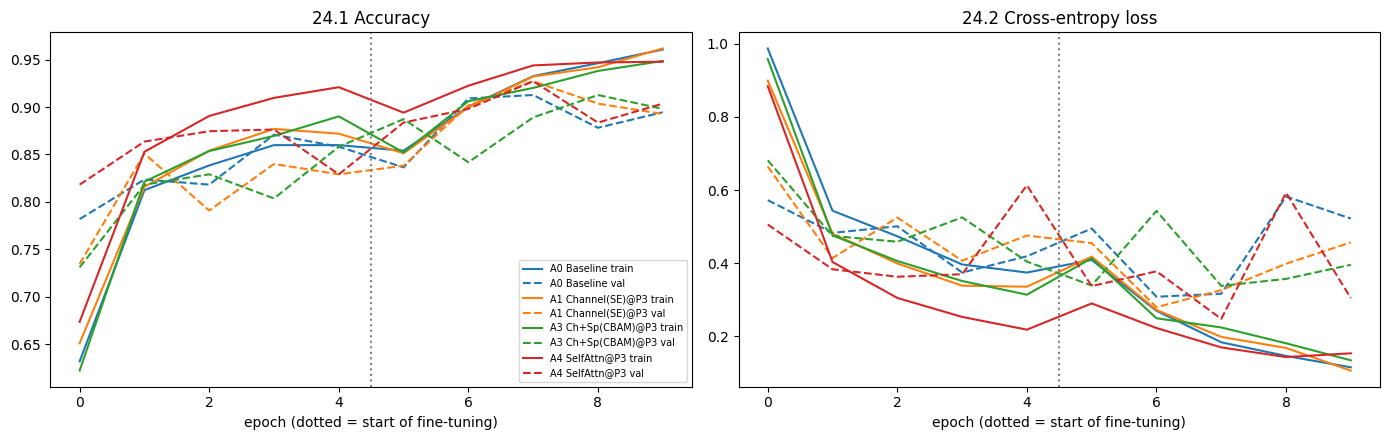

In [ ]:
def hist_of(name):
    a, k = NAMED[ALIAS.get(name, name)]
    hs = [json.load(open(f"{OUT}/{key_of(a, k)}_s{sd}.json"))["hist"] for sd in SEEDS]
    return {m: np.mean([h[m] for h in hs], 0) for m in hs[0]}
SEL = [n for n in ["A0 Baseline", "A1 Channel(SE)@P3", "A3 Ch+Sp(CBAM)@P3", "A4 SelfAttn@P3"] if n in NAMED]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for n in SEL:
    h = hist_of(n); c = ax[0].plot(h["accuracy"], label=n + " train")[0].get_color()
    ax[0].plot(h["val_accuracy"], "--", color=c, label=n + " val")
    ax[1].plot(h["loss"], color=c, label=n + " train"); ax[1].plot(h["val_loss"], "--", color=c, label=n + " val")
for a_, t in zip(ax, ["24.1 Accuracy", "24.2 Cross-entropy loss"]):
    a_.axvline(EP_HEAD - 0.5, color="gray", ls=":"); a_.set_xlabel("epoch (dotted = start of fine-tuning)"); a_.set_title(t)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(OUT + "/curves.png", dpi=150); plt.show()

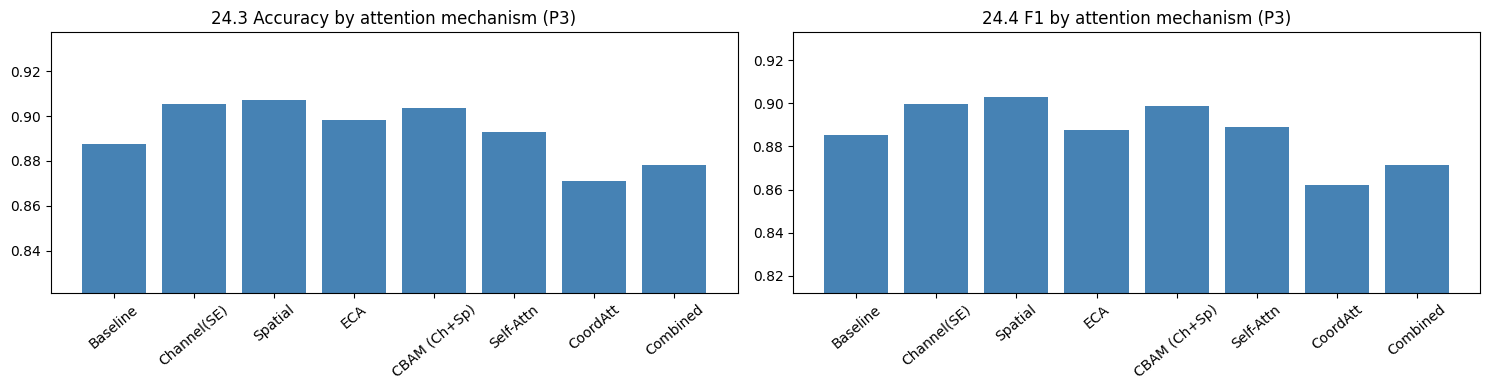

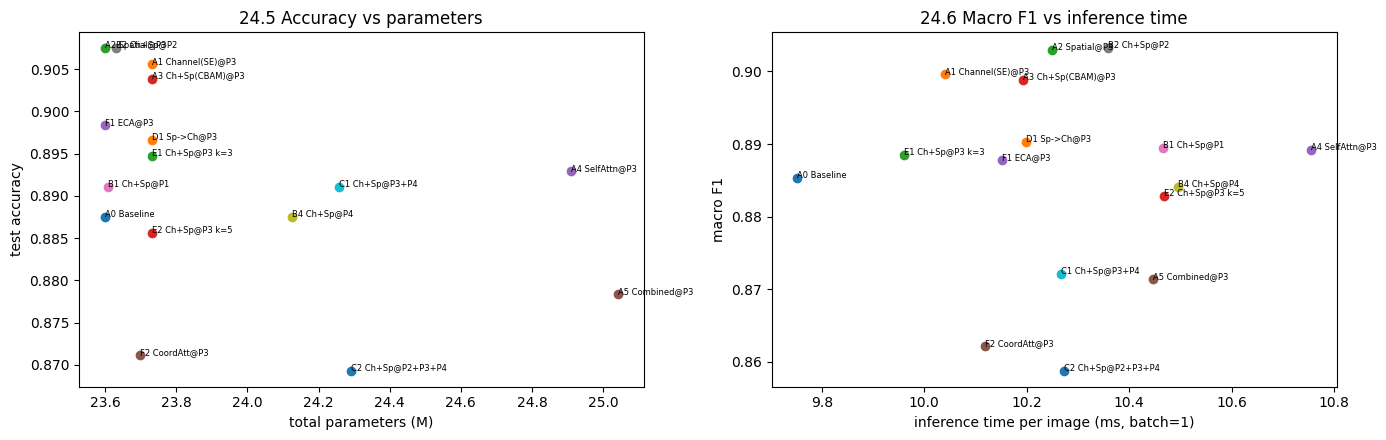

In [ ]:
MECH = [("Baseline", "A0 Baseline"), ("Channel(SE)", "A1 Channel(SE)@P3"), ("Spatial", "A2 Spatial@P3"), ("ECA", "F1 ECA@P3"),
        ("CBAM (Ch+Sp)", "A3 Ch+Sp(CBAM)@P3"), ("Self-Attn", "A4 SelfAttn@P3"), ("CoordAtt", "F2 CoordAtt@P3"), ("Combined", "A5 Combined@P3")]
MECH = [(a, b) for a, b in MECH if b in agg.index]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a_, m in zip(ax, ["Accuracy", "F1"]):
    v = [agg.loc[b, m] for _, b in MECH]; e = [agg.loc[b, m + "_std"] for _, b in MECH] if len(SEEDS) > 1 else None
    a_.bar([a for a, _ in MECH], v, yerr=e, color="steelblue"); a_.set_ylim(max(0, min(v) - 0.05), min(1, max(v) + 0.03))
    a_.set_title(f"24.{3 if m == 'Accuracy' else 4} {m} by attention mechanism (P3)"); a_.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.savefig(OUT + "/bars.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for n, r in agg.iterrows():
    ax[0].scatter(r.TotalParams / 1e6, r.Accuracy); ax[0].annotate(n, (r.TotalParams / 1e6, r.Accuracy), fontsize=6)
    ax[1].scatter(r.ms_per_img, r.F1);              ax[1].annotate(n, (r.ms_per_img, r.F1), fontsize=6)
ax[0].set(xlabel="total parameters (M)", ylabel="test accuracy", title="24.5 Accuracy vs parameters")
ax[1].set(xlabel="inference time per image (ms, batch=1)", ylabel="macro F1", title="24.6 Macro F1 vs inference time")
plt.tight_layout(); plt.savefig(OUT + "/tradeoffs.png", dpi=150); plt.show()

## 9. Confusion matrices and class-wise analysis

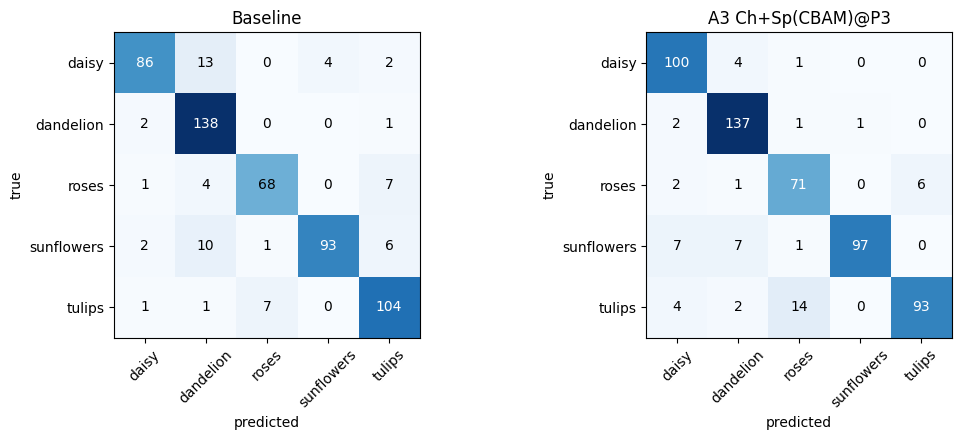

,baseline F1,attention F1,delta
daisy,0.8731,0.9091,0.0360
dandelion,0.8990,0.9384,0.0393
roses,0.8718,0.8452,-0.0266
sunflowers,0.8900,0.9238,0.0339
tulips,0.8927,0.8774,-0.0153


Class benefiting most from attention: dandelion (+0.0393 F1)
Most frequent confusions (true -> predicted, count)
 baseline : [('daisy', 'dandelion', 13), ('sunflowers', 'dandelion', 10), ('tulips', 'roses', 7)] 
 attention: [('tulips', 'roses', 14), ('sunflowers', 'dandelion', 7), ('sunflowers', 'daisy', 7)]


,daisy,dandelion,roses,sunflowers,tulips
A0 Baseline,0.873,0.899,0.872,0.890,0.893
A1 Channel(SE)@P3,0.916,0.953,0.840,0.915,0.875
A2 Spatial@P3,0.928,0.936,0.855,0.931,0.865
A3 Ch+Sp(CBAM)@P3,0.909,0.938,0.845,0.924,0.877
A4 SelfAttn@P3,0.899,0.912,0.843,0.912,0.881
A5 Combined@P3,0.877,0.908,0.809,0.882,0.881
B1 Ch+Sp@P1,0.924,0.894,0.857,0.924,0.849
B2 Ch+Sp@P2,0.928,0.935,0.865,0.908,0.880
B4 Ch+Sp@P4,0.912,0.907,0.854,0.869,0.879
C1 Ch+Sp@P3+P4,0.907,0.961,0.704,0.932,0.856


In [ ]:
SELECTED = "A3 Ch+Sp(CBAM)@P3"
def preds_of(name):
    a, k = NAMED[ALIAS.get(name, name)]
    r = json.load(open(f"{OUT}/{key_of(a, k)}_s{SEEDS[0]}.json")); return np.array(r["y_pred"]), np.array(r["f1_per_class"])
(pb, fb), (pa, fa) = preds_of("A0 Baseline"), preds_of(SELECTED)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a_, p, t in zip(ax, [pb, pa], ["Baseline", SELECTED]):
    cm = confusion_matrix(test_y, p, labels=range(5)); a_.imshow(cm, cmap="Blues"); a_.set_title(t)
    a_.set_xticks(range(5)); a_.set_xticklabels(CLASSES, rotation=45); a_.set_yticks(range(5)); a_.set_yticklabels(CLASSES)
    a_.set_xlabel("predicted"); a_.set_ylabel("true")
    for i in range(5):
        for j in range(5): a_.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig(OUT + "/confusion.png", dpi=150); plt.show()

cls = pd.DataFrame({"baseline F1": fb, "attention F1": fa, "delta": fa - fb}, index=CLASSES).round(4); display(cls)
print("Class benefiting most from attention:", cls.delta.idxmax(), f"({cls.delta.max():+.4f} F1)")
def top_conf(p, n=3):
    cm = confusion_matrix(test_y, p, labels=range(5)); np.fill_diagonal(cm, 0)
    return [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i, j in zip(*np.unravel_index(np.argsort(cm, axis=None)[::-1][:n], cm.shape))]
print("Most frequent confusions (true -> predicted, count)\n baseline :", top_conf(pb), "\n attention:", top_conf(pa))

# class-wise F1 for every model
pcf = pd.DataFrame({n: preds_of(n)[1] for n in agg.index}, index=CLASSES).T.round(3); display(pcf)

## 10. Visualisation helpers (Grad-CAM, internal attention maps)

In [ ]:
def overlay(ax, img, m, title="", cmap="jet"):
    ax.imshow(img)
    if m is not None: ax.imshow(tf.image.resize(np.asarray(m, "float32")[..., None], (224, 224))[..., 0].numpy(), cmap=cmap, alpha=0.45, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8); ax.axis("off")

_cache = {}
def get_net(name):
    att, k = NAMED[ALIAS.get(name, name)]; key = key_of(att, k)
    if key not in _cache:
        if len(_cache) >= 8: _cache.clear(); gc.collect()
        net = Net(att, k); net(tf.zeros((1, 224, 224, 3))); net.load_weights(f"{OUT}/ckpt/{key}.weights.h5"); _cache[key] = net
    return _cache[key]

def run_to(net, x, p):                       # feature BEFORE and AFTER the attention at position p (earlier attention applied)
    h = tf.convert_to_tensor(x[None])
    for i in range(1, p + 1):
        h = net.stages[i - 1](h, training=False)
        if i < p and f"p{i}" in net.atts: h = net.atts[f"p{i}"](h)
    pre = h; post = net.atts[f"p{p}"](pre) if f"p{p}" in net.atts else pre
    return pre, post

def unwrap(a): return a.layers[0] if isinstance(a, keras.Sequential) else a

def spatial_map(net, x, p):                  # internal spatial-attention map M_s at position p
    pre, _ = run_to(net, x, p); m = unwrap(net.atts[f"p{p}"]).get_map(pre)[0, ..., 0].numpy()
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

def channel_weights(net, x, p):
    pre, _ = run_to(net, x, p); a = unwrap(net.atts[f"p{p}"]); a = a.ca if isinstance(a, CBAM) else a
    return a.weights_of(pre)[0].numpy()

def self_attn_maps(net, x, p, query=None):   # attention of a query / mean / max over queries, each reshaped to H x W
    pre, _ = run_to(net, x, p); sa = [l for l in ([net.atts[f"p{p}"]] + list(getattr(net.atts[f"p{p}"], "layers", []))) if isinstance(l, SelfAttn)][0]
    h = pre
    if isinstance(net.atts[f"p{p}"], keras.Sequential): h = net.atts[f"p{p}"].layers[0](pre)
    _, A = sa(h, return_attn=True); A = A[0].numpy(); H, W = sa.H, sa.W
    q = (H // 2) * W + W // 2 if query is None else query
    nz = lambda m: (m - m.min()) / (m.max() - m.min() + 1e-8)
    return nz(A[q].reshape(H, W)), nz(A.mean(0).reshape(H, W)), nz(A.max(0).reshape(H, W)), (H // 2, W // 2)

def gradcam(net, x):                          # Grad-CAM on the last feature map (after P4 attention if present)
    with tf.GradientTape() as t:
        logits, feat = net(tf.convert_to_tensor(x[None]), return_feat=True)
        c = int(tf.argmax(logits[0])); score = logits[:, c]
    w = tf.reduce_mean(t.gradient(score, feat), (1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * feat, -1))[0]
    return (cam / (tf.reduce_max(cam) + 1e-8)).numpy(), c

def predict(net, x): return int(tf.argmax(net(tf.convert_to_tensor(x[None]), training=False)[0]))

## 11. Feature maps before / after attention, channel weights, spatial attention (one model at P3)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


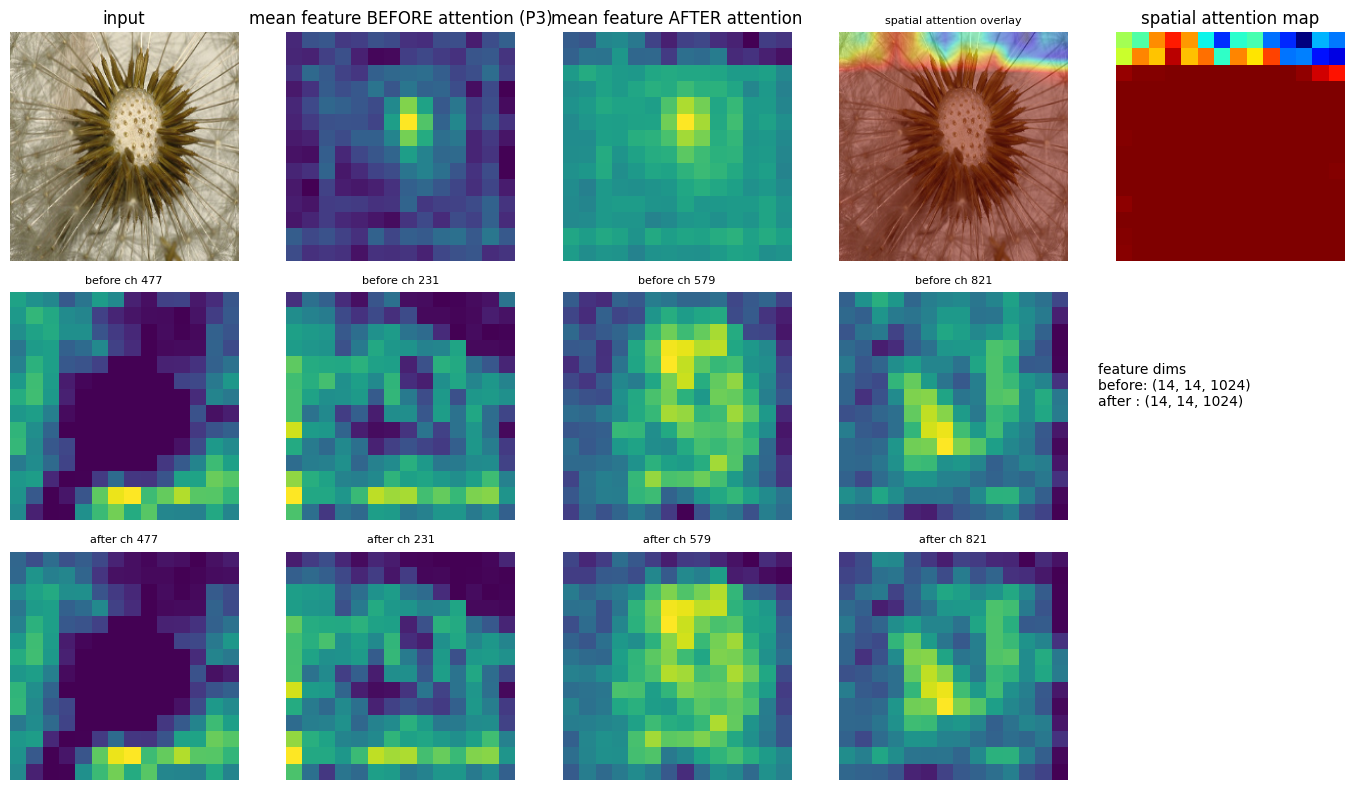

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


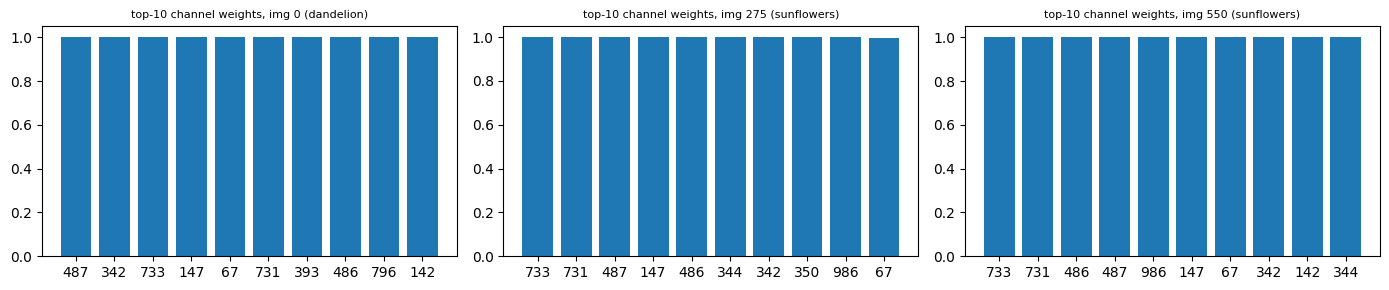

channels=1024 | mean weight 0.637 | fraction of weights > 0.5: 0.643 | mean per-channel std across images 0.0129 | top-10 channels' mean weight 0.999


In [ ]:
IMG = 0
net = get_net(SELECTED); x = prep_np(IMG); pre, post = run_to(net, x, 3)
pre_, post_ = pre[0].numpy(), post[0].numpy(); top = np.argsort(pre_.mean((0, 1)))[::-1][:4]
fig, ax = plt.subplots(3, 5, figsize=(14, 8))
ax[0, 0].imshow(test_raw[IMG]); ax[0, 0].set_title("input"); ax[0, 1].imshow(pre_.mean(-1), cmap="viridis"); ax[0, 1].set_title("mean feature BEFORE attention (P3)")
ax[0, 2].imshow(post_.mean(-1), cmap="viridis"); ax[0, 2].set_title("mean feature AFTER attention")
overlay(ax[0, 3], test_raw[IMG], spatial_map(net, x, 3), "spatial attention overlay"); ax[0, 4].imshow(spatial_map(net, x, 3), cmap="jet"); ax[0, 4].set_title("spatial attention map")
for j, c in enumerate(top):
    ax[1, j].imshow(pre_[..., c]); ax[1, j].set_title(f"before ch {c}", fontsize=8); ax[2, j].imshow(post_[..., c]); ax[2, j].set_title(f"after ch {c}", fontsize=8)
for a_ in ax.ravel(): a_.axis("off")
ax[1, 4].text(0, .5, f"feature dims\nbefore: {pre_.shape}\nafter : {post_.shape}"); plt.tight_layout(); plt.savefig(OUT + "/feature_maps.png", dpi=150); plt.show()

# channel-attention weights (Top-10) for several images + variability over images
net_c = get_net("A1 Channel(SE)@P3"); ids = np.linspace(0, len(test_y) - 1, 3).astype(int)
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a_, i in zip(ax, ids):
    w = channel_weights(net_c, prep_np(i), 3); t = np.argsort(w)[::-1][:10]
    a_.bar(range(10), w[t], tick_label=t); a_.set_title(f"top-10 channel weights, img {i} ({CLASSES[test_y[i]]})", fontsize=8)
plt.tight_layout(); plt.show()
W = np.stack([channel_weights(net_c, prep_np(i), 3) for i in np.linspace(0, len(test_y) - 1, min(40, len(test_y))).astype(int)])
print(f"channels={W.shape[1]} | mean weight {W.mean():.3f} | fraction of weights > 0.5: {(W > .5).mean():.3f} | "
      f"mean per-channel std across images {W.std(0).mean():.4f} | top-10 channels' mean weight {np.sort(W.mean(0))[::-1][:10].mean():.3f}")

## 12. Self-attention response (query location · mean · max)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


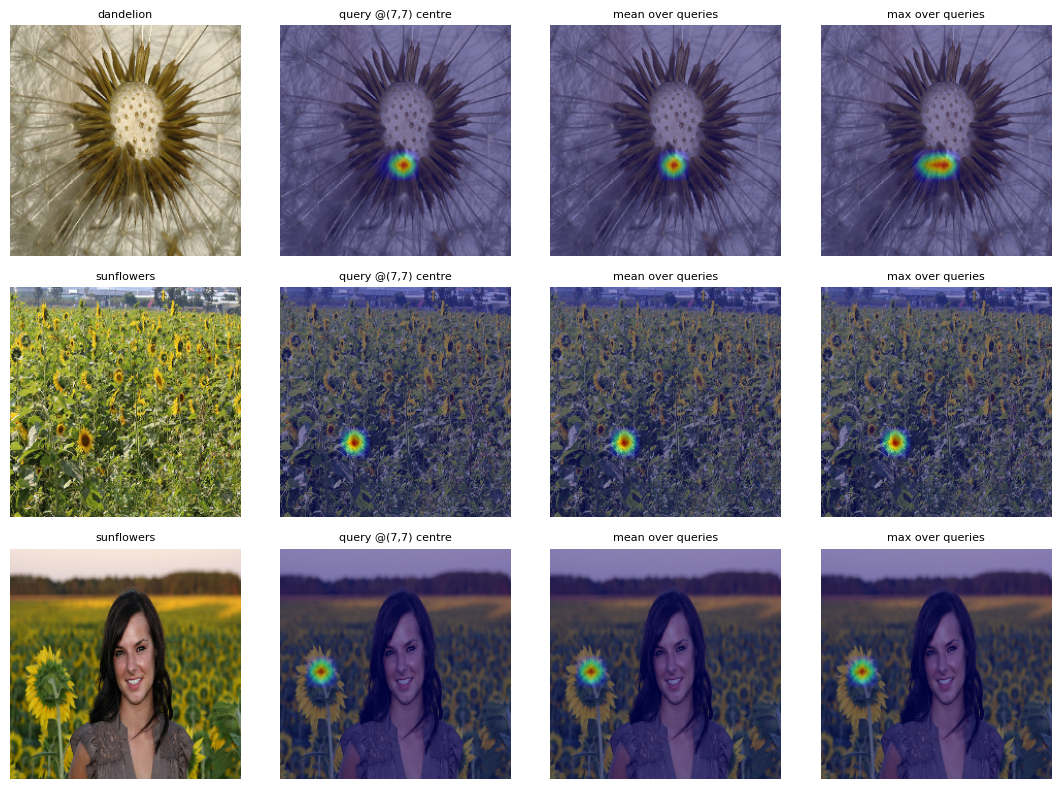

learned gamma: 0.06206789240241051 (0 at init; >0 means attention branch is actually used)
self-attention matrix size at P2/P3/P4: N^2 = 614656 / 38416 / 2401


In [ ]:
net_s = get_net("A4 SelfAttn@P3"); fig, ax = plt.subplots(3, 4, figsize=(11, 8))
for r, i in enumerate(np.linspace(0, len(test_y) - 1, 3).astype(int)):
    q, mean, mx, (qh, qw) = self_attn_maps(net_s, prep_np(i), 3)
    ax[r, 0].imshow(test_raw[i]); ax[r, 0].set_title(f"{CLASSES[test_y[i]]}", fontsize=8)
    overlay(ax[r, 1], test_raw[i], q, f"query @({qh},{qw}) centre"); overlay(ax[r, 2], test_raw[i], mean, "mean over queries"); overlay(ax[r, 3], test_raw[i], mx, "max over queries")
    ax[r, 0].axis("off")
plt.tight_layout(); plt.savefig(OUT + "/self_attention.png", dpi=150); plt.show()
print("learned gamma:", float(net_s.atts["p3"].gamma.numpy()), "(0 at init; >0 means attention branch is actually used)")
print("self-attention matrix size at P2/P3/P4: N^2 =", (28 * 28) ** 2, "/", (14 * 14) ** 2, "/", (7 * 7) ** 2)

## 13. Attention position visualisation: input | M_s^P2 | M_s^P3 | M_s^P4

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_3', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_4', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


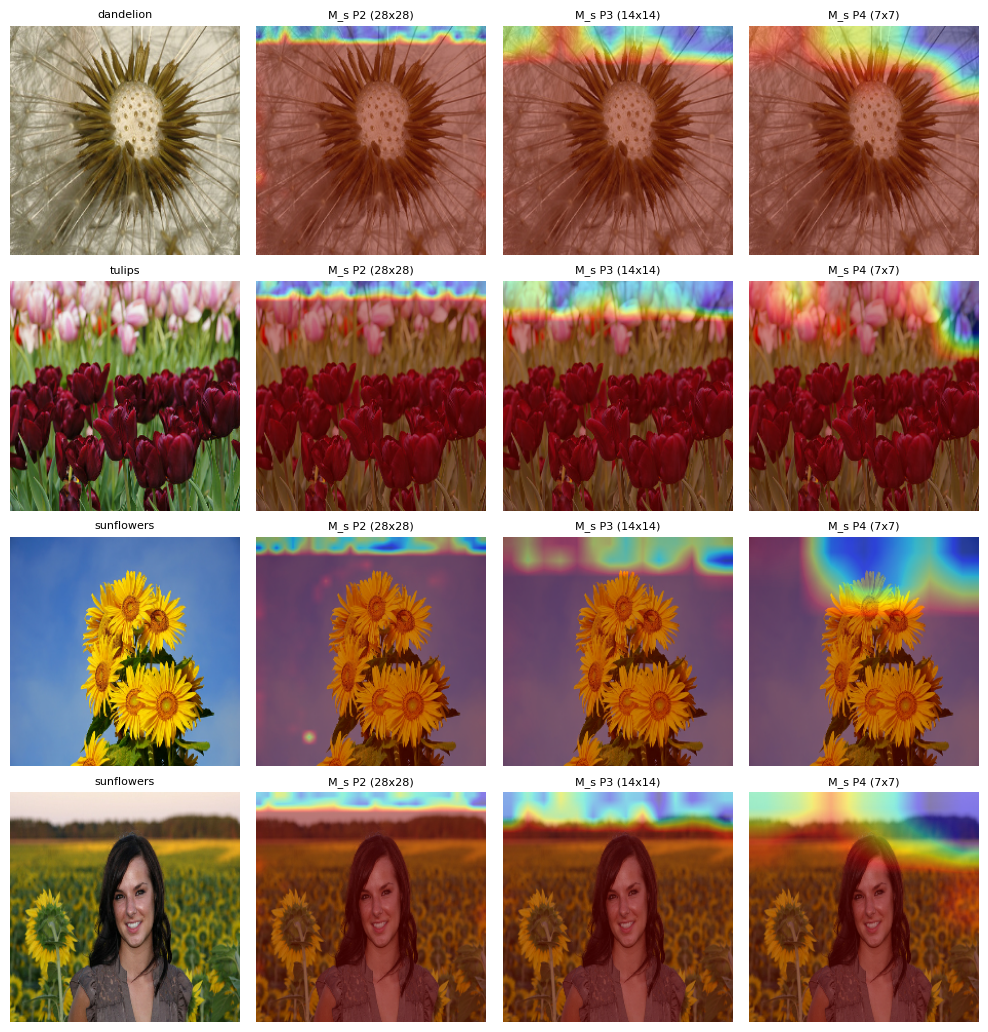

In [ ]:
pos_models = [("P2", "B2 Ch+Sp@P2", 2), ("P3", "A3 Ch+Sp(CBAM)@P3", 3), ("P4", "B4 Ch+Sp@P4", 4)]
ids = np.linspace(0, len(test_y) - 1, 4).astype(int)
fig, ax = plt.subplots(len(ids), 4, figsize=(10, 2.6 * len(ids)))
for r, i in enumerate(ids):
    ax[r, 0].imshow(test_raw[i]); ax[r, 0].axis("off"); ax[r, 0].set_title(CLASSES[test_y[i]], fontsize=8)
    for c, (lab, nm, p) in enumerate(pos_models, 1):
        m = spatial_map(get_net(nm), prep_np(i), p); overlay(ax[r, c], test_raw[i], m, f"M_s {lab} ({m.shape[0]}x{m.shape[1]})")
plt.tight_layout(); plt.savefig(OUT + "/attention_positions.png", dpi=150); plt.show()

## 14. Grad-CAM comparisons (3 correct + 2 incorrect images)

correct: [np.int64(517), np.int64(412), np.int64(155)] | incorrect (attention model): [np.int64(466), np.int64(235)]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_5', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_6', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


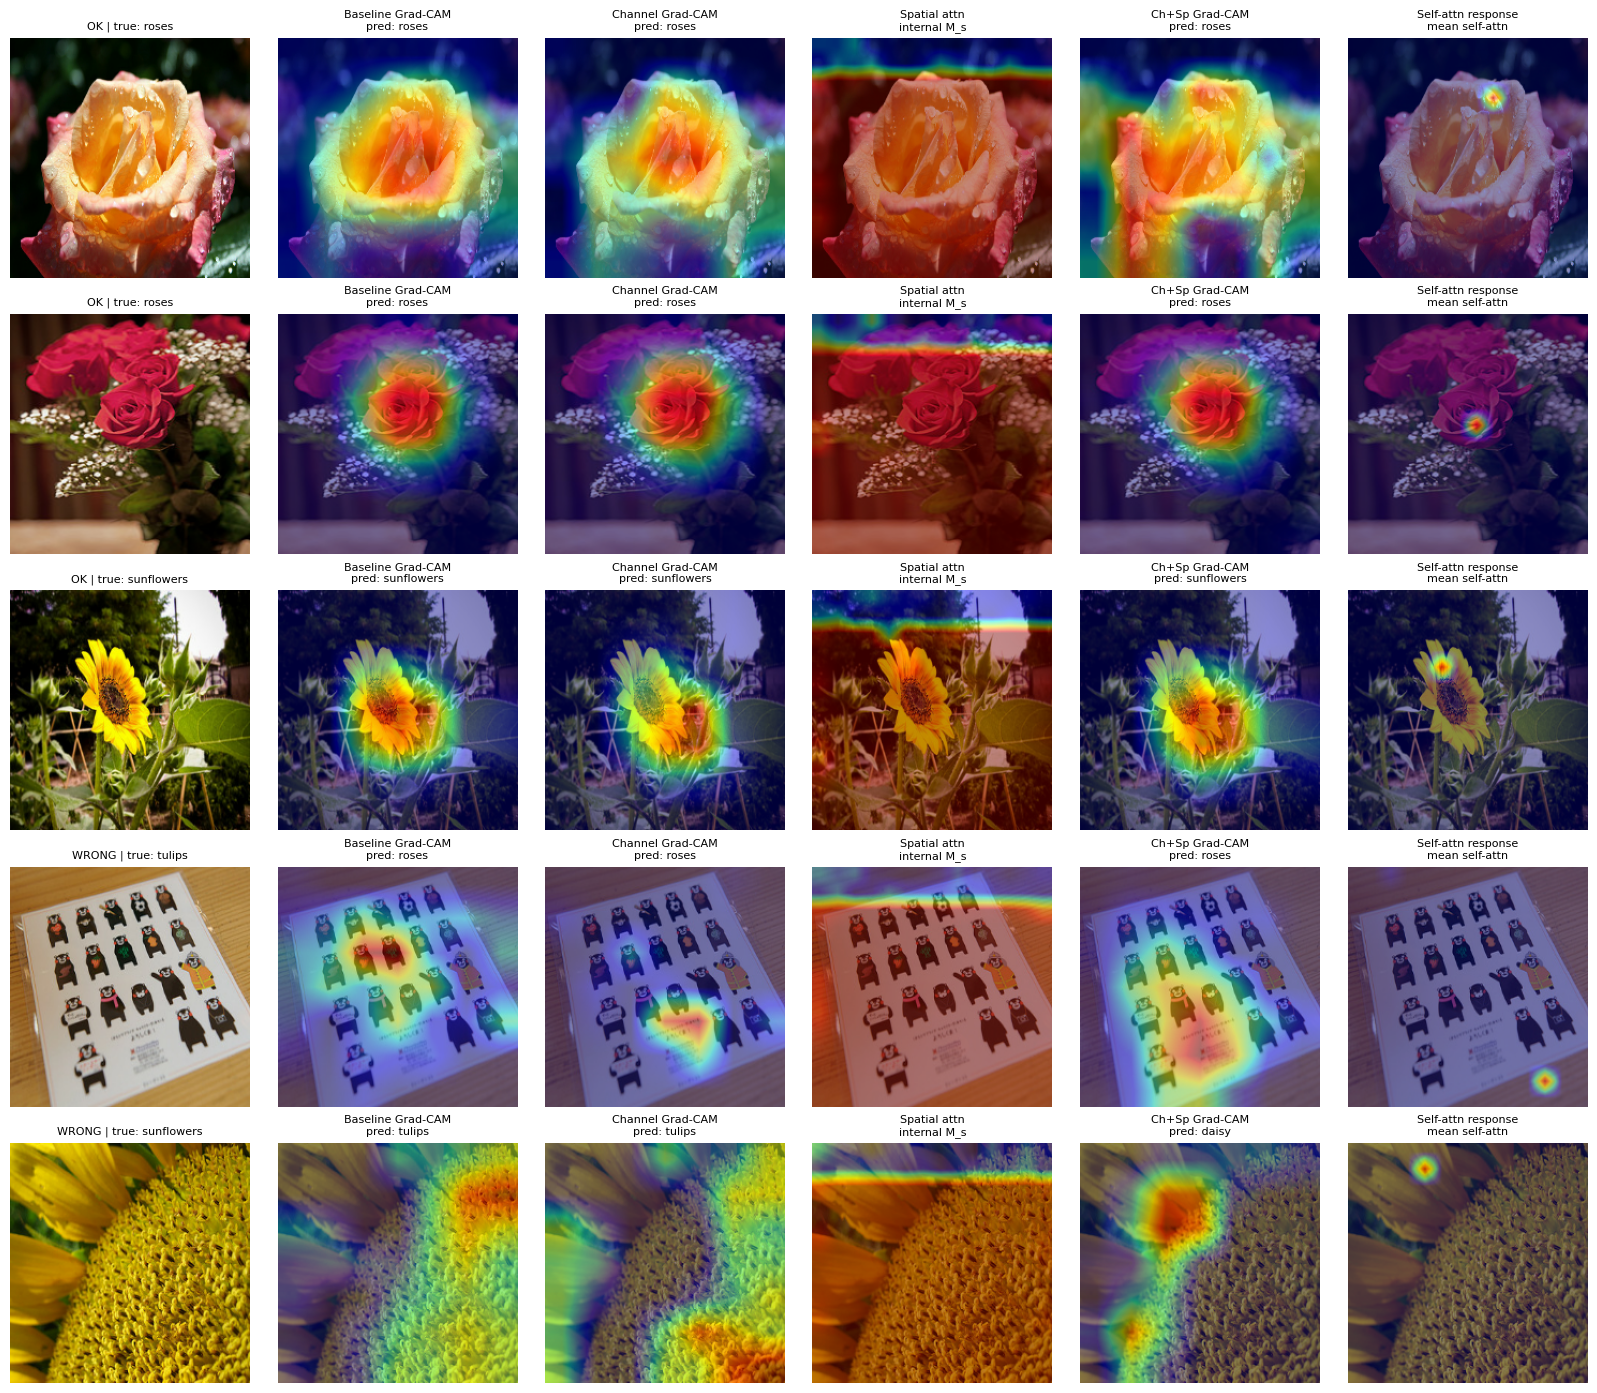

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_7', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_8', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_9', however the layer does not have a `build()` m

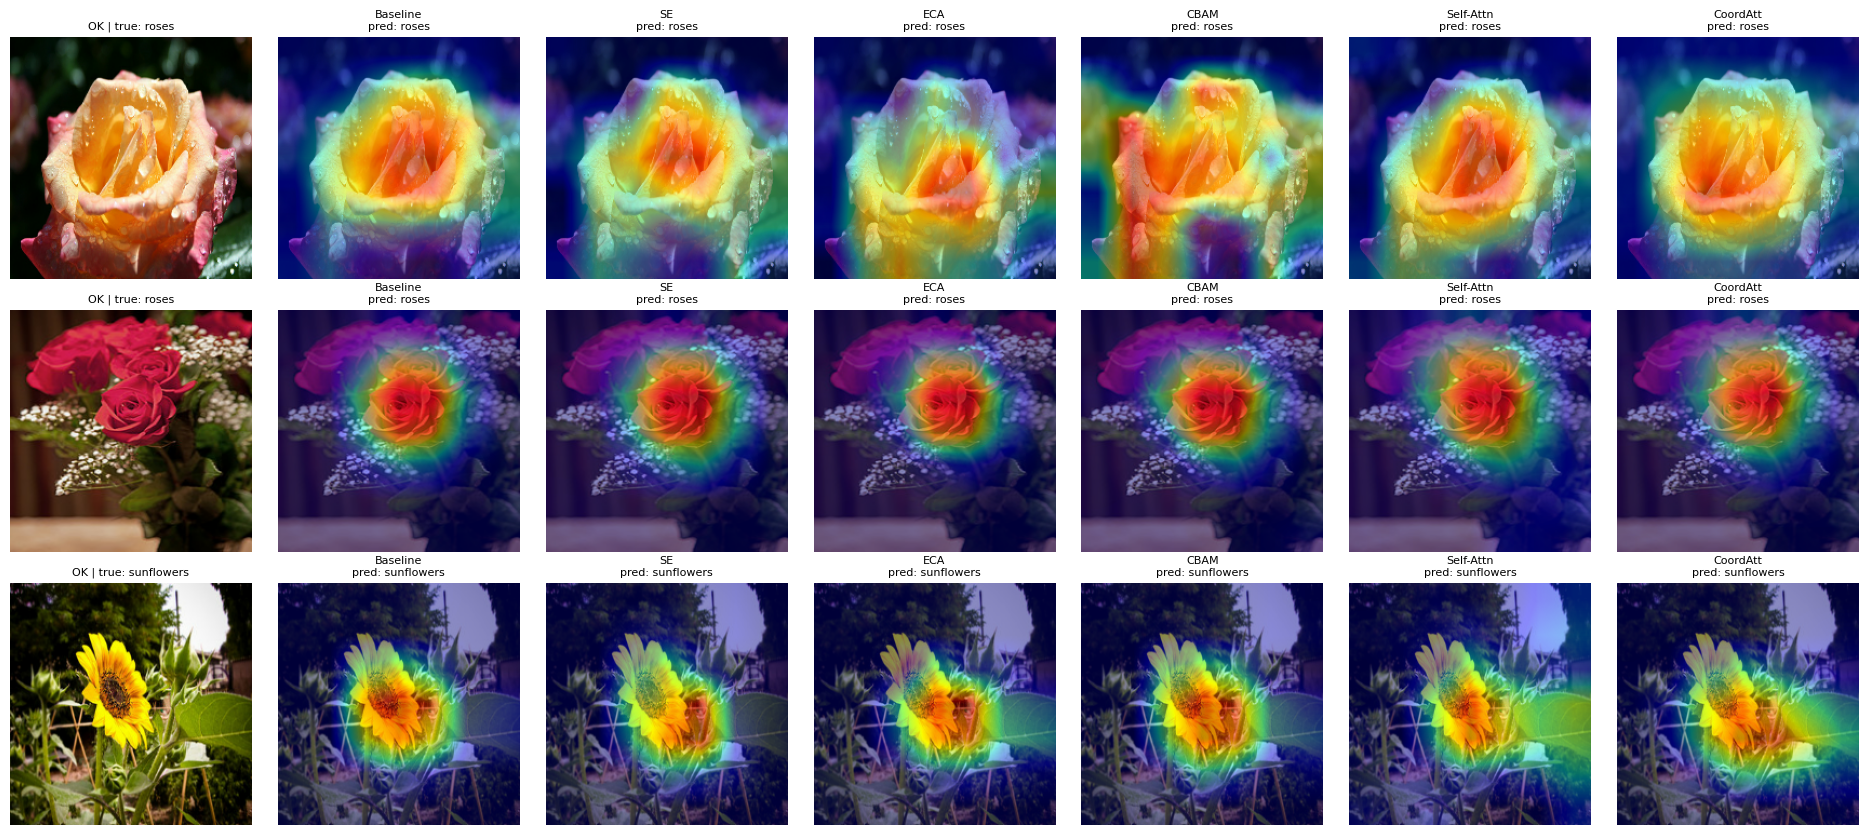

In [ ]:
def choose(arr, n, rng):
    arr = np.asarray(arr); return arr if len(arr) <= n else rng.choice(arr, n, replace=False)
pa_, pb_ = preds_of(SELECTED)[0], preds_of("A0 Baseline")[0]; rng = np.random.RandomState(0)
idx_ok  = choose(np.where((pa_ == test_y) & (pb_ == test_y))[0], 3, rng)
idx_bad = choose(np.where(pa_ != test_y)[0], 2, rng)
IDX = list(idx_ok) + list(idx_bad); print("correct:", list(idx_ok), "| incorrect (attention model):", list(idx_bad))

def gc_col(name):
    def f(i):
        cam, c = gradcam(get_net(name), prep_np(i)); return cam, f"pred: {CLASSES[c]}"
    return f
def sp_col(name, p): return lambda i: (spatial_map(get_net(name), prep_np(i), p), "internal M_s")
def sa_col(name, p): return lambda i: (self_attn_maps(get_net(name), prep_np(i), p)[1], "mean self-attn")

def grid(idxs, cols, fname):
    fig, ax = plt.subplots(len(idxs), len(cols) + 1, figsize=(2.7 * (len(cols) + 1), 2.8 * len(idxs)), squeeze=False)
    for r, i in enumerate(idxs):
        ax[r, 0].imshow(test_raw[i]); ax[r, 0].set_title(f"{'OK' if r < len(idx_ok) else 'WRONG'} | true: {CLASSES[test_y[i]]}", fontsize=8); ax[r, 0].axis("off")
        for c, (hd, fn) in enumerate(cols, 1):
            m, cap = fn(i); overlay(ax[r, c], test_raw[i], m, f"{hd}\n{cap}")
    plt.tight_layout(); plt.savefig(OUT + "/" + fname, dpi=150); plt.show()

grid(IDX, [("Baseline Grad-CAM", gc_col("A0 Baseline")), ("Channel Grad-CAM", gc_col("A1 Channel(SE)@P3")),
           ("Spatial attn", sp_col("A2 Spatial@P3", 3)), ("Ch+Sp Grad-CAM", gc_col(SELECTED)),
           ("Self-attn response", sa_col("A4 SelfAttn@P3", 3))], "qualitative_main.png")
# extended: Input | Baseline | SE | ECA | CBAM | Self-Attention
grid(IDX[:3], [("Baseline", gc_col("A0 Baseline")), ("SE", gc_col("A1 Channel(SE)@P3")), ("ECA", gc_col("F1 ECA@P3")),
               ("CBAM", gc_col(SELECTED)), ("Self-Attn", gc_col("A4 SelfAttn@P3")), ("CoordAtt", gc_col("F2 CoordAtt@P3"))], "qualitative_extended.png")

In [ ]:
# Grad-CAM statistics over many test images (so conclusions are not based on a single image)
def cam_stats(name, n=50):
    net = get_net(name); cov, conc = [], []
    for i in np.linspace(0, len(test_y) - 1, min(n, len(test_y))).astype(int):
        cam, _ = gradcam(net, prep_np(i)); m = tf.image.resize(cam[..., None], (224, 224))[..., 0].numpy()
        cov.append((m > 0.5).mean()); s = np.sort(m.ravel())[::-1]; conc.append(s[: len(s) // 10].sum() / (s.sum() + 1e-8))
    return np.mean(cov), np.mean(conc)
names = [n for n in ["A0 Baseline", "A1 Channel(SE)@P3", "A3 Ch+Sp(CBAM)@P3", "A4 SelfAttn@P3", "F1 ECA@P3", "F2 CoordAtt@P3", "B2 Ch+Sp@P2", "B4 Ch+Sp@P4"] if n in NAMED]
cs = pd.DataFrame({n: cam_stats(n) for n in names}, index=["coverage (area with CAM>0.5)", "concentration (CAM mass in top-10% pixels)"]).T.round(3); display(cs)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_14', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'net_15', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


,coverage (area with CAM>0.5),concentration (CAM mass in top-10% pixels)
A0 Baseline,0.244,0.315
A1 Channel(SE)@P3,0.258,0.309
A3 Ch+Sp(CBAM)@P3,0.214,0.334
A4 SelfAttn@P3,0.284,0.260
F1 ECA@P3,0.213,0.341
F2 CoordAtt@P3,0.362,0.250
B2 Ch+Sp@P2,0.230,0.337
B4 Ch+Sp@P4,0.240,0.293


## 15. Feature-dimension log (manual section 38, item 1)

In [ ]:
rows = []
for n, (a, k) in NAMED.items():
    p = f"{OUT}/{key_of(a, k)}_s{SEEDS[0]}.json"
    if os.path.exists(p):
        for pos, (i, o) in json.load(open(p))["dims"].items(): rows.append(dict(Model=n, Position=pos, Before=tuple(i), After=tuple(o), Unchanged=(i == o)))
display(pd.DataFrame(rows))

,Model,Position,Before,After,Unchanged
0,A1 Channel(SE)@P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True
1,A2 Spatial@P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True
2,A3 Ch+Sp(CBAM)@P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True
3,A4 SelfAttn@P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True
4,A5 Combined@P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True
5,B1 Ch+Sp@P1,P1,"(56, 56, 256)","(56, 56, 256)",True
6,B2 Ch+Sp@P2,P2,"(28, 28, 512)","(28, 28, 512)",True
7,B4 Ch+Sp@P4,P4,"(7, 7, 2048)","(7, 7, 2048)",True
8,C1 Ch+Sp@P3+P4,P3,"(14, 14, 1024)","(14, 14, 1024)",True
9,C1 Ch+Sp@P3+P4,P4,"(7, 7, 2048)","(7, 7, 2048)",True
